In [11]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('data1.csv')

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [13]:
data.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

## Univariate

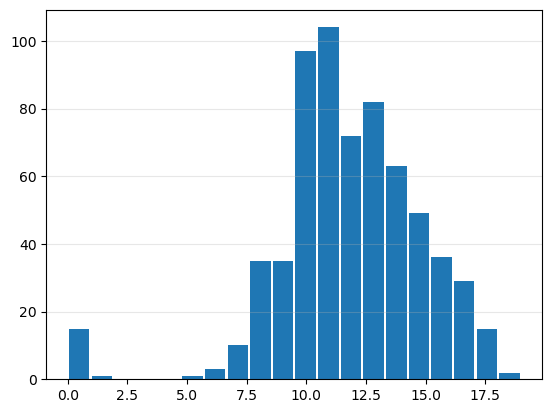

In [14]:
target = 'G3'
plt.hist(data[target], bins=20, rwidth = 0.9)
plt.grid(axis='y', alpha=0.3)
plt.show()

In [15]:
print((data[target]==0).sum() / data.shape[0])

0.023112480739599383


['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


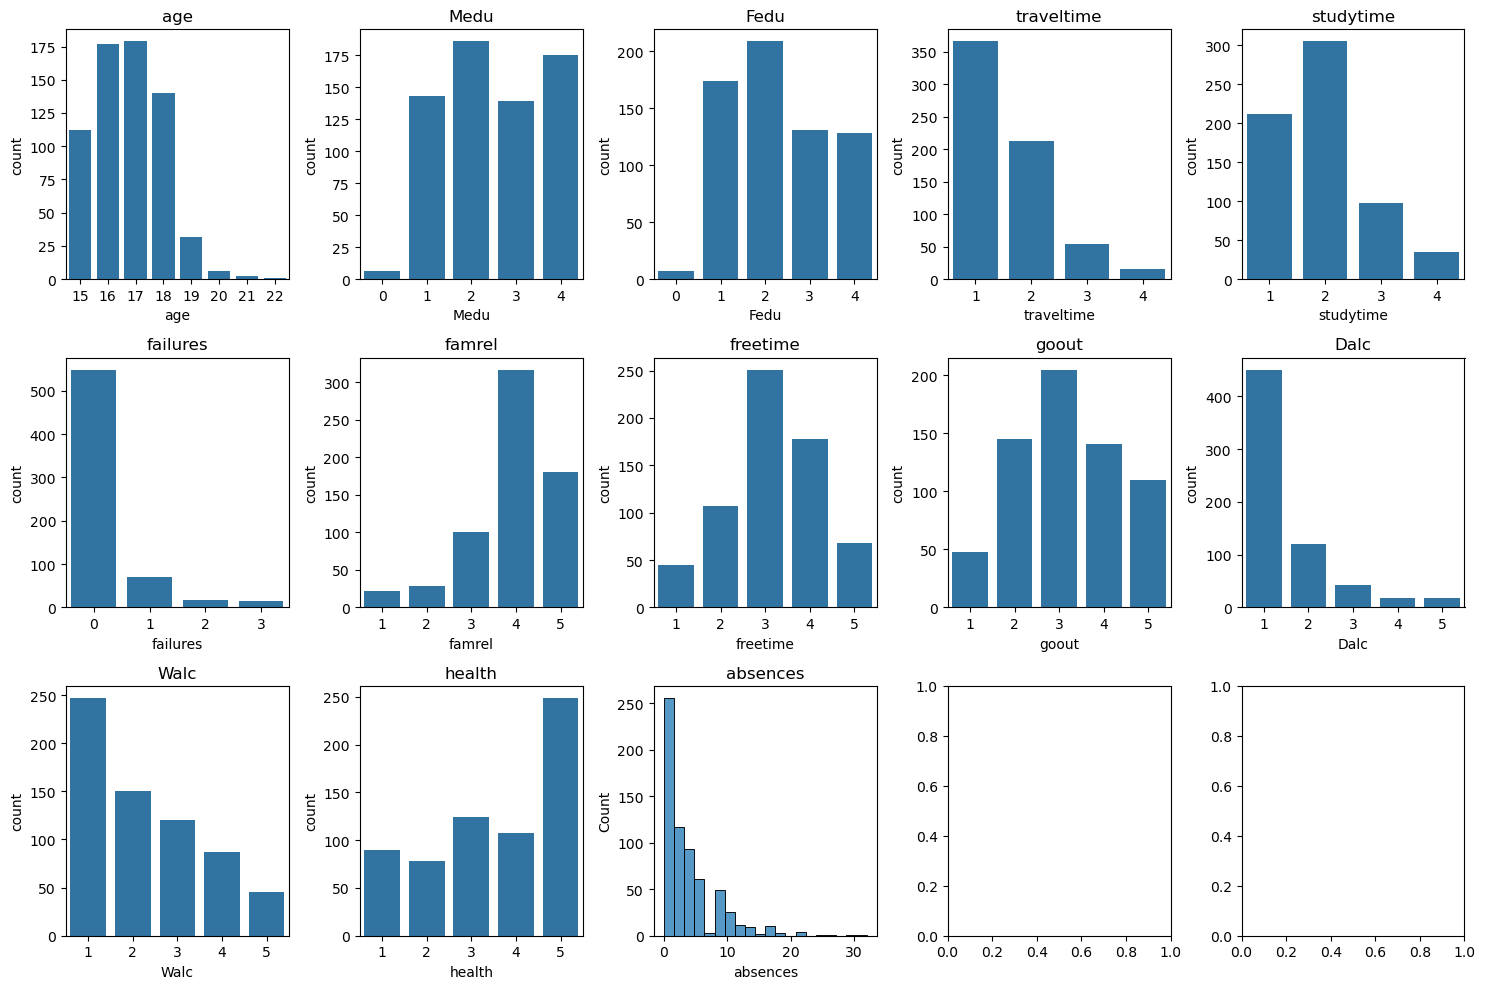

In [16]:
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
print(numeric_features)
fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(15, 10))

for ax, feature in zip(axes.flat, numeric_features):
    if feature == 'absences':
        sns.histplot(data=data, x=feature, ax=ax, bins=20)
    else:
        sns.countplot(data=data,  x=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

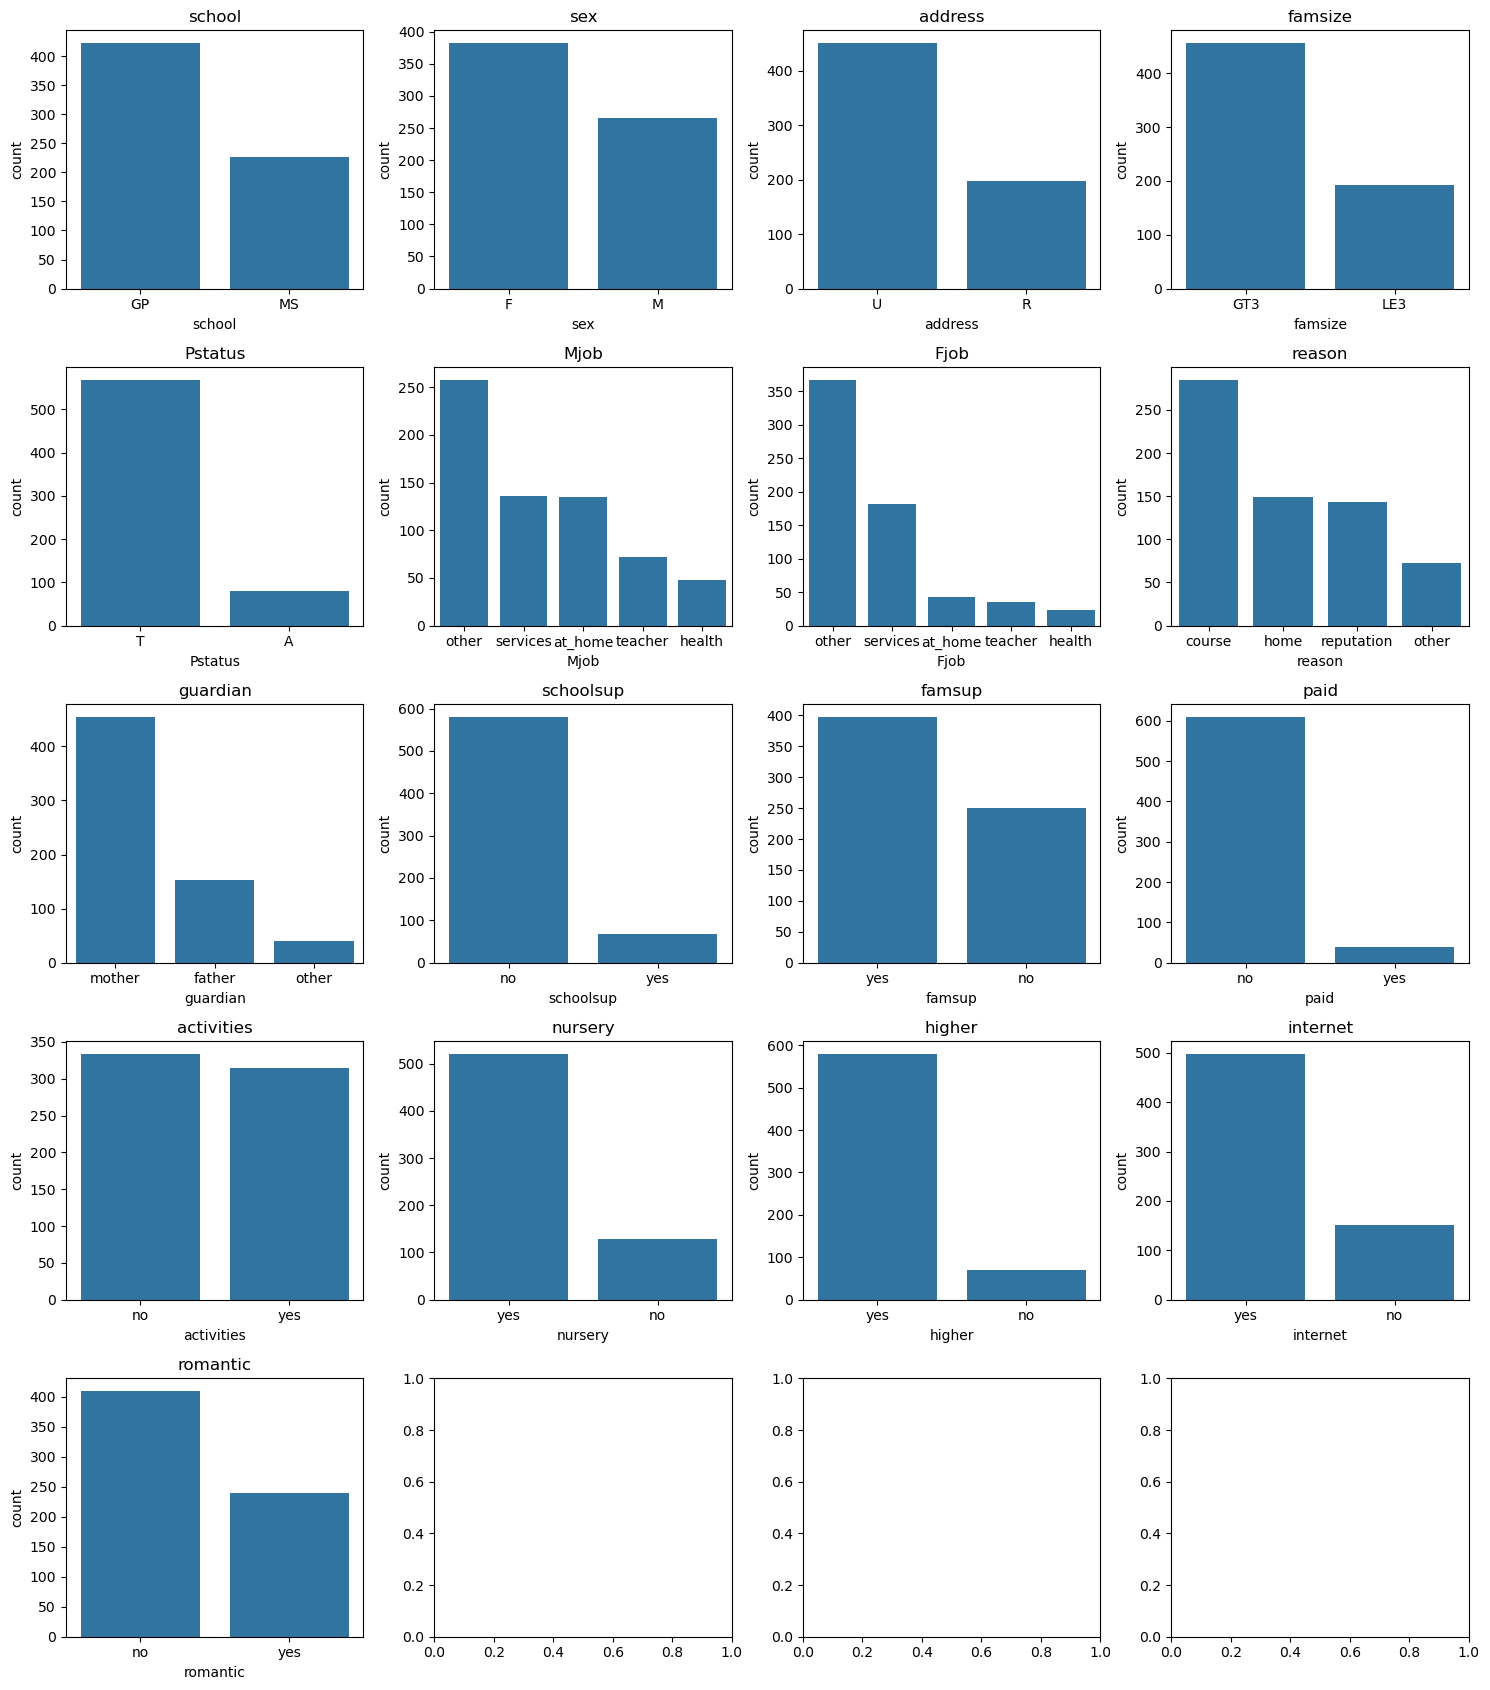

In [17]:
categorical_features = data.select_dtypes(include=['object']).columns.tolist()

fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(15, 17))

for ax, feature in zip(axes.flat, categorical_features):
    order = data[feature].value_counts().index  
    sns.countplot(data=data,  x=feature, ax=ax, order=order)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## Bivariate

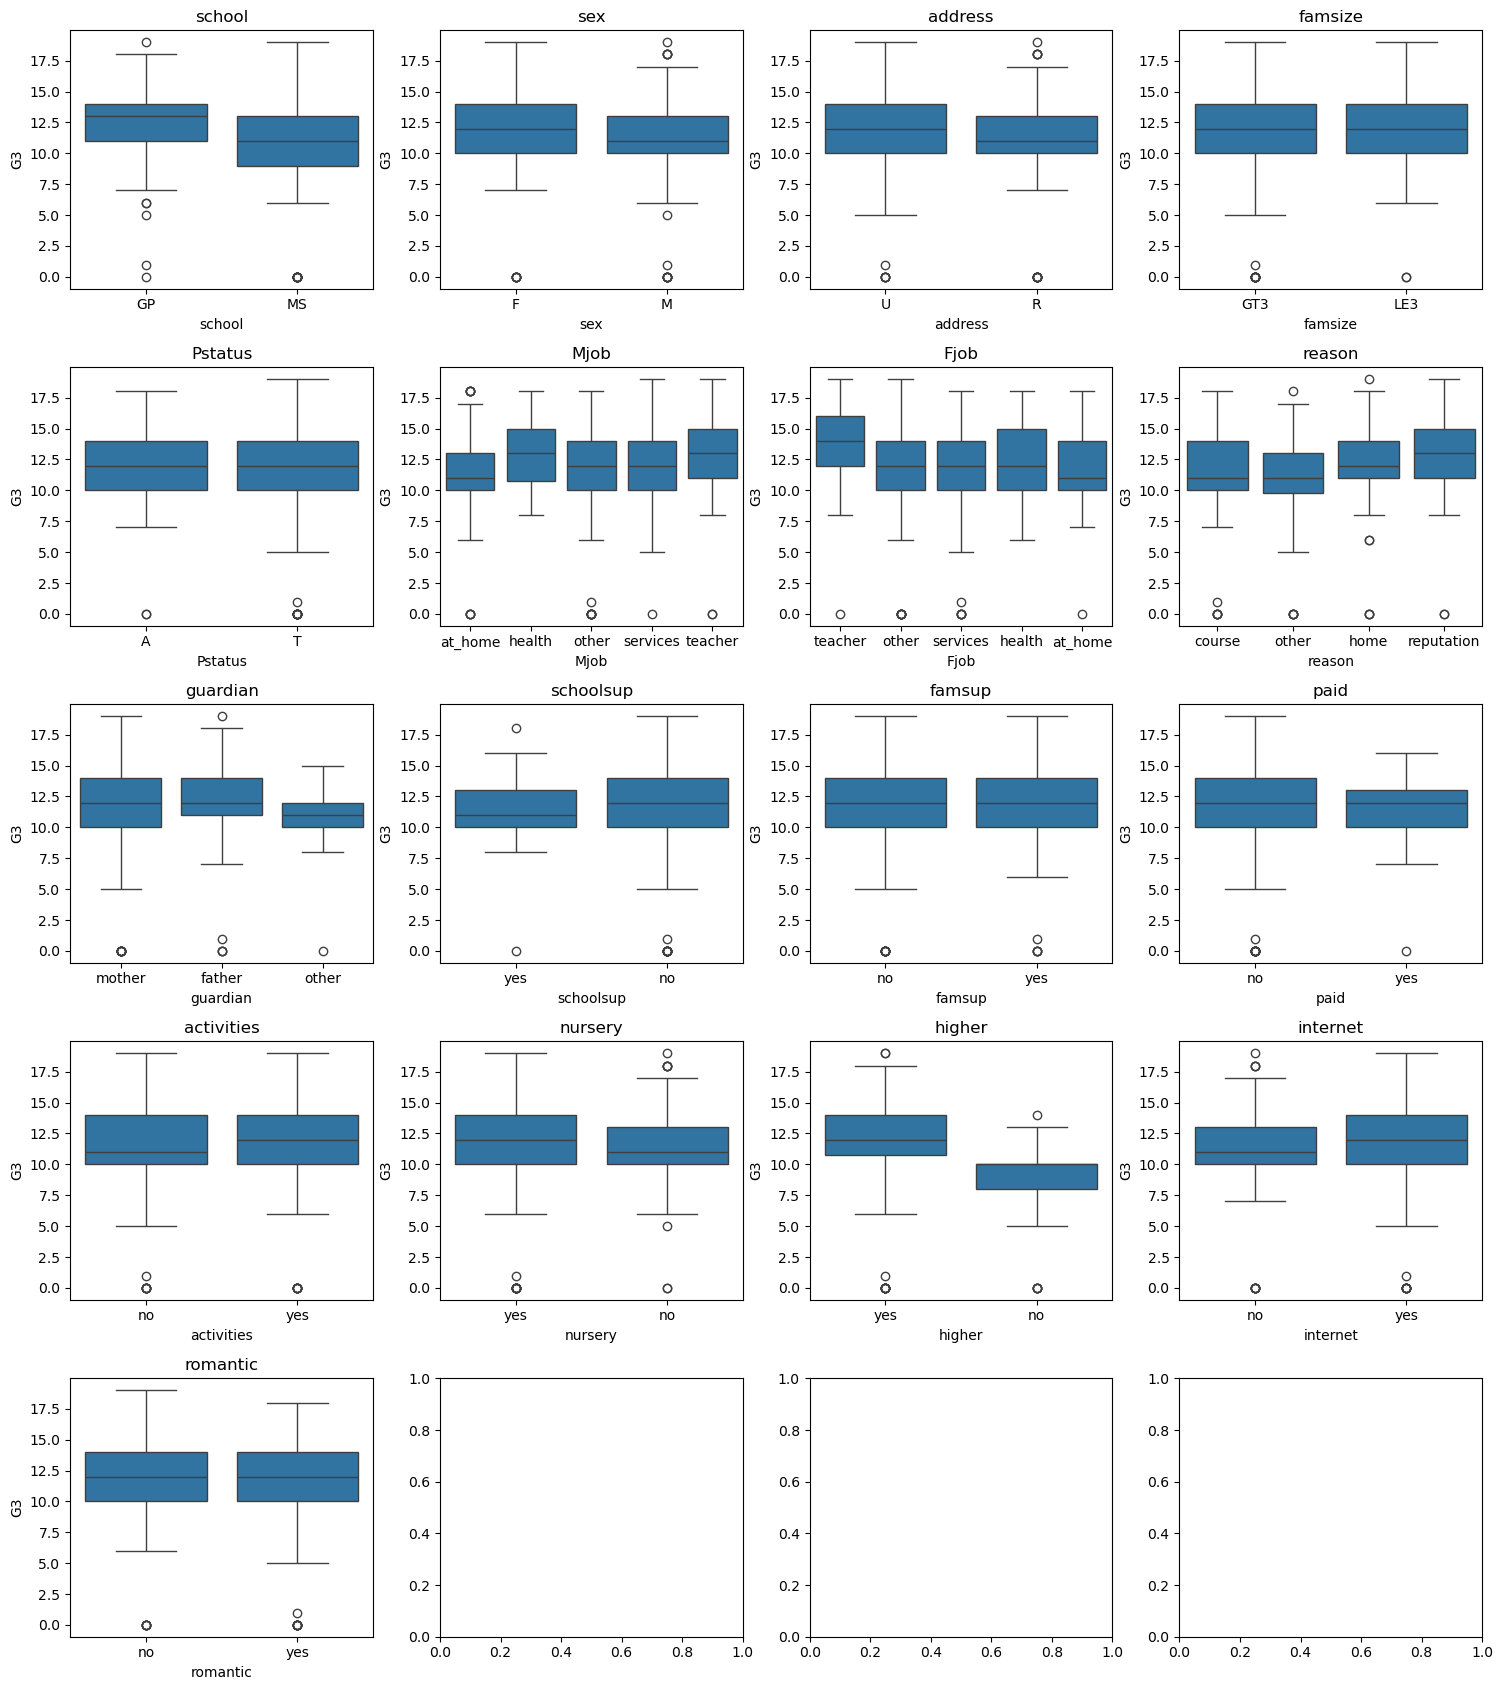

In [18]:
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(15, 17))

for ax, feature in zip(axes.flat, categorical_features):
    sns.boxplot(data=data, x=feature, y=target, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

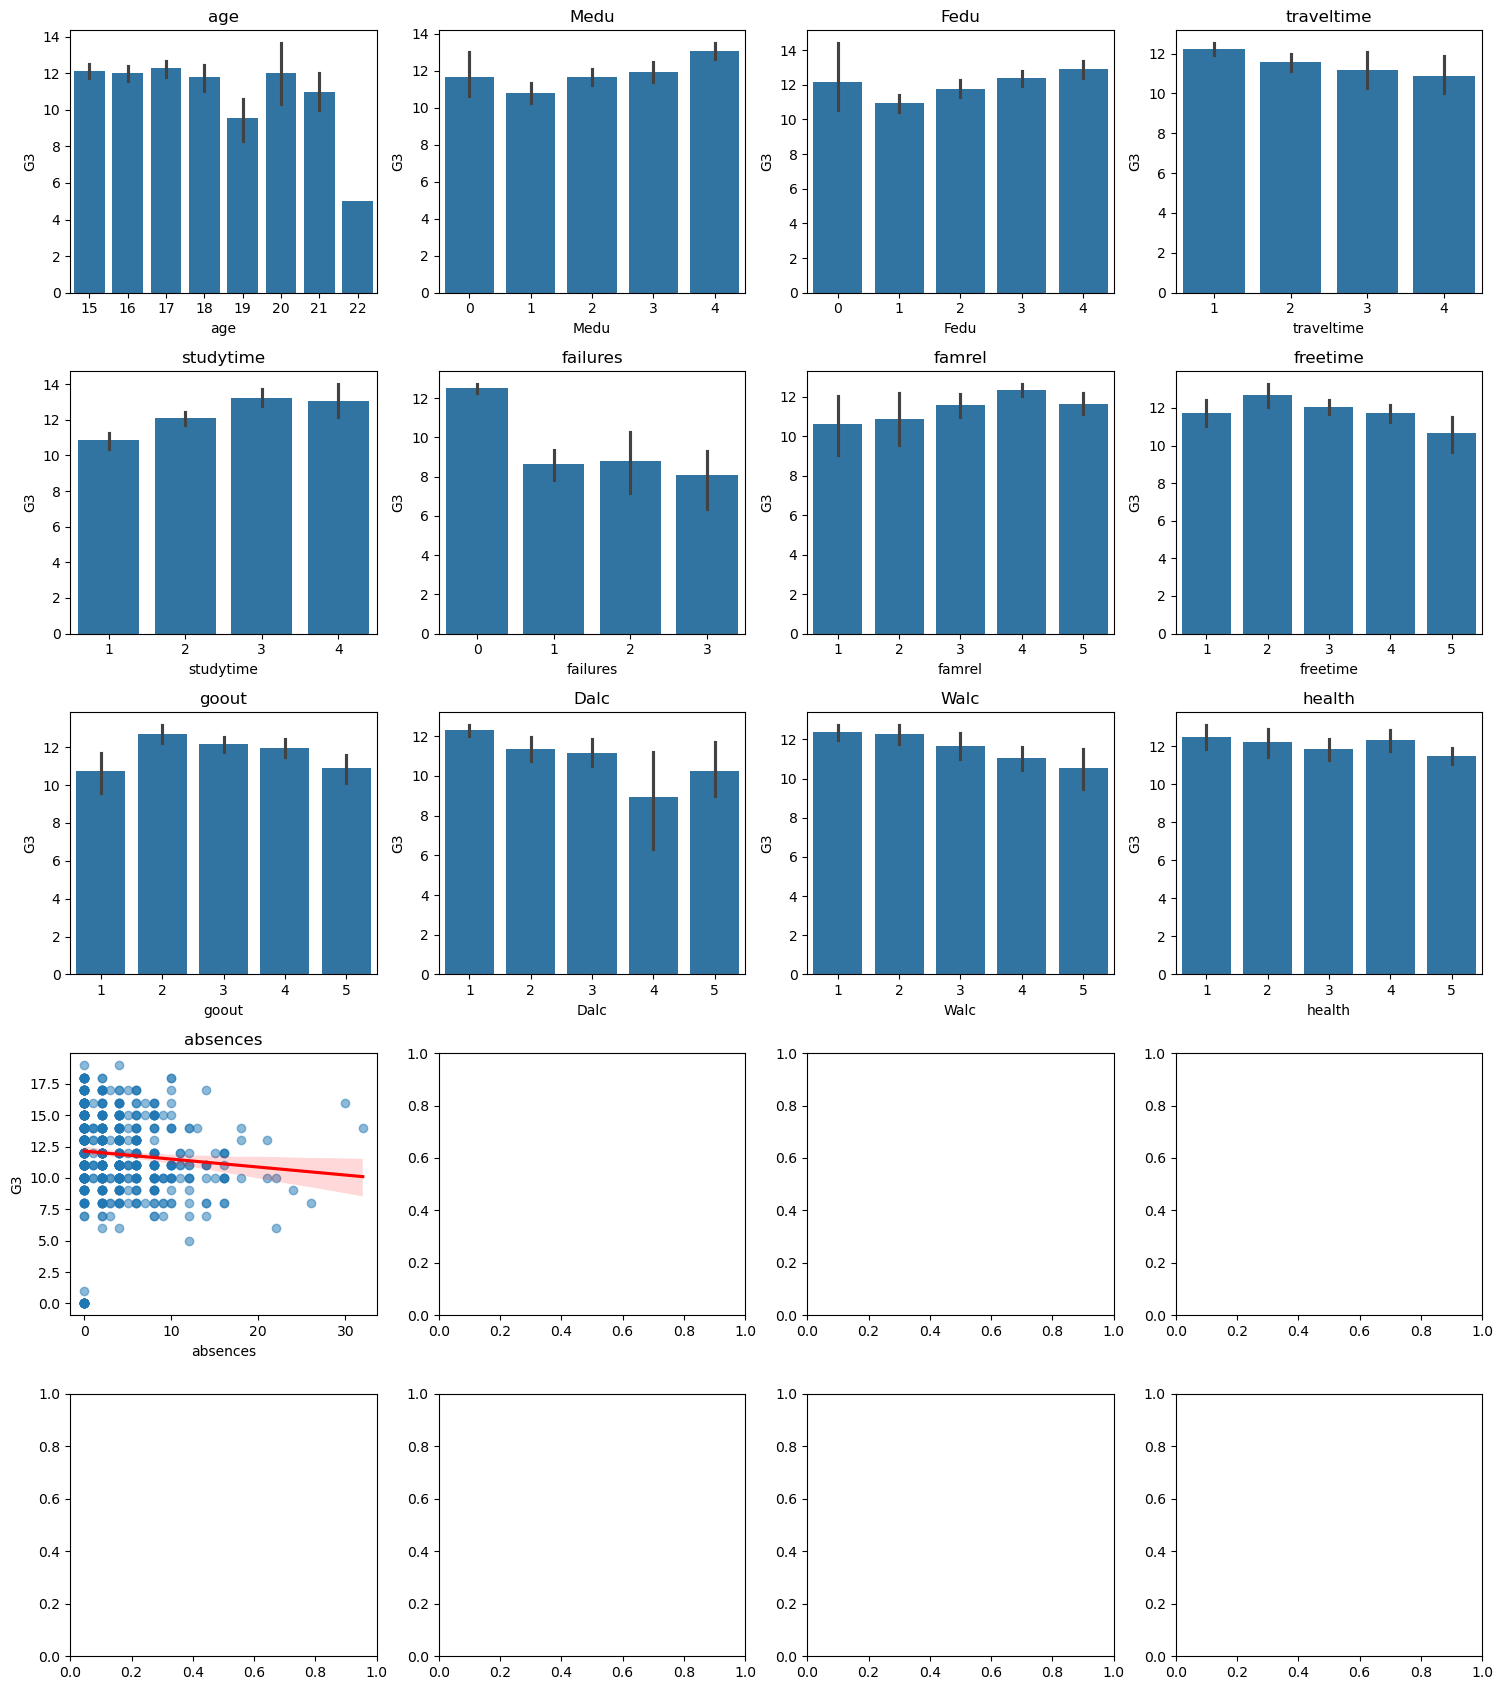

In [19]:
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(15, 17))

for ax, feature in zip(axes.flat, numeric_features):
    if feature == 'absences':
        sns.regplot(data=data, x=feature, y=target, ax=ax, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
    else:
        sns.barplot(data=data, x=feature, y=target, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## Multivariate

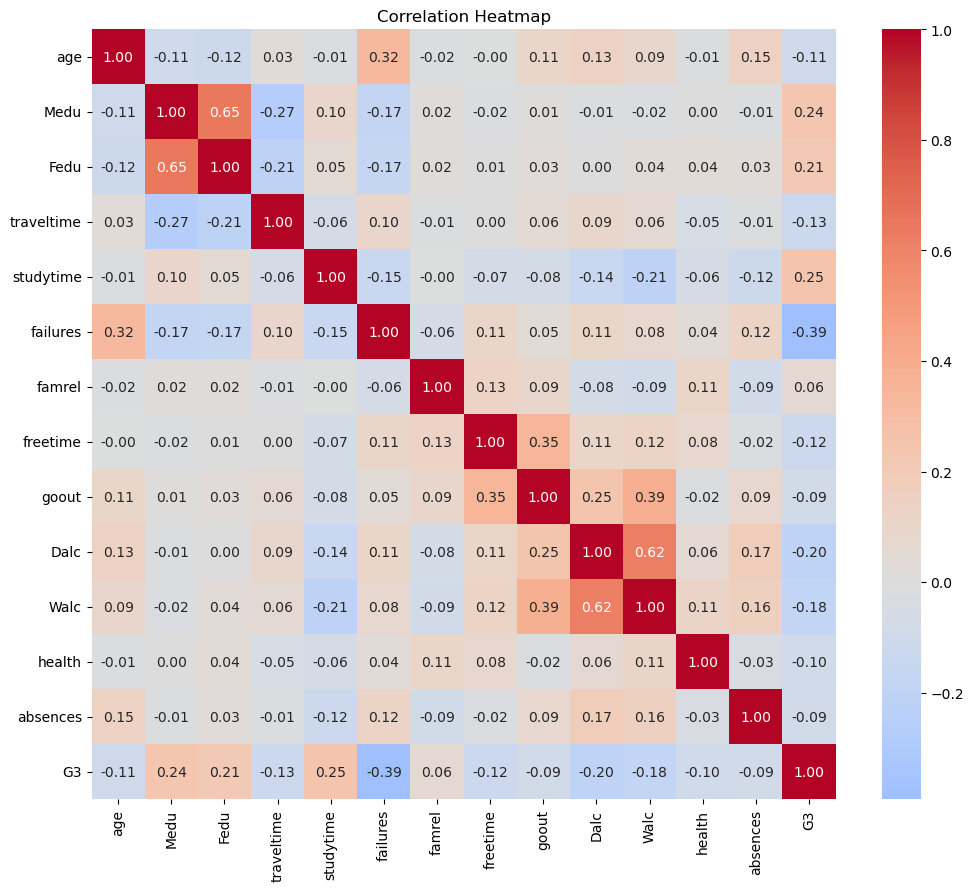

In [20]:
plt.figure(figsize=(12, 10))
sns.heatmap(data[numeric_features + [target]].corr(method='pearson'), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Heatmap')
plt.show()

In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_const = add_constant(data[numeric_features])
print (X_const.head())
vif = pd.DataFrame({
    "feature": X_const.columns,
    "VIF": [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
})

vif_df = vif[vif['feature'] != 'const'].sort_values(by='VIF', ascending=False)
print(vif_df)

   const  age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  \
0    1.0   18     4     4           2          2         0       4         3   
1    1.0   17     1     1           1          2         0       5         3   
2    1.0   15     1     1           1          2         0       4         3   
3    1.0   15     4     2           1          3         0       3         2   
4    1.0   16     3     3           1          2         0       4         3   

   goout  Dalc  Walc  health  absences  
0      4     1     1       3         4  
1      3     1     1       3         2  
2      2     2     3       3         6  
3      2     1     1       5         0  
4      2     1     2       5         0  
       feature       VIF
11        Walc  1.898820
2         Medu  1.806310
3         Fedu  1.761638
10        Dalc  1.663791
9        goout  1.370399
6     failures  1.198411
8     freetime  1.187311
1          age  1.168318
4   traveltime  1.098958
5    studytime  1.08910

## modeling

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, train_test_split

X  = data[numeric_features + categorical_features]
Y = data[target]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', "passthrough", numeric_features),    
        ('cat', OneHotEncoder(drop='first'), categorical_features),
    ])

model = Pipeline(
    [
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ])
scores = cross_val_score(model, X, Y, cv=5, scoring='neg_root_mean_squared_error')
print(f"RMSE CV: {-scores.mean():.2f} (± {scores.std():.2f})")

RMSE CV: 2.74 (± 0.72)


In [23]:
import statsmodels.formula.api as smf

formula = ("G3 ~ failures + studytime + Medu + Fedu + Dalc + traveltime"
           " + C(sex) + C(school) + C(Mjob) + C(Fjob) + C(reason) + C(guardian)")
model = smf.ols(formula, data=data).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.298
Model:                            OLS   Adj. R-squared:                  0.274
Method:                 Least Squares   F-statistic:                     12.67
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           4.05e-36
Time:                        13:01:00   Log-Likelihood:                -1566.7
No. Observations:                 649   AIC:                             3177.
Df Residuals:                     627   BIC:                             3276.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

In [24]:
from sklearn.linear_model import LogisticRegression

model1 = LogisticRegression(max_iter=1000)
model1.fit(data[['G1']], (data[target]>=10).astype(int))
print("sklearn:", model1.coef_.round(3), model1.intercept_.round(3))

sklearn: [[1.198]] [-9.861]


In [25]:
import statsmodels.api as sm

logit1 = sm.Logit((data[target]>=10).astype(int), sm.add_constant(data[["G1"]])).fit()
print(logit1.params.round(3))
print(logit1.summary())

Optimization terminated successfully.
         Current function value: 0.212454
         Iterations 9
const   -10.012
G1        1.215
dtype: float64
                           Logit Regression Results                           
Dep. Variable:                     G3   No. Observations:                  649
Model:                          Logit   Df Residuals:                      647
Method:                           MLE   Df Model:                            1
Date:                Sat, 10 Oct 2026   Pseudo R-squ.:                  0.5056
Time:                        13:01:01   Log-Likelihood:                -137.88
converged:                       True   LL-Null:                       -278.89
Covariance Type:            nonrobust   LLR p-value:                 2.725e-63
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.0119      1.077     -9.294      0.000     -1